In [6]:
import skfuzzy as fuzz
import numpy as np
import cv2
import matplotlib.pyplot as plt

0.0 0.3027360162815125 0.34863199185924376
0.710061630120798


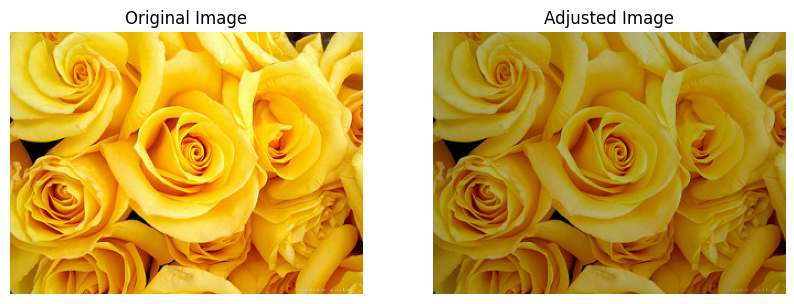

In [25]:
def fuzzy_brightness(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    average_brightness = np.mean(gray_image) 

    x_brightness = np.arange(0, 256, 1)
    low = fuzz.trimf(x_brightness, [0, 0, 128])
    medium = fuzz.trimf(x_brightness, [64, 128, 192])
    high = fuzz.trimf(x_brightness, [128, 256, 256])

    # Calculate the fuzzy membership values for the average brightness
    low_membership = fuzz.interp_membership(x_brightness, low, average_brightness)
    medium_membership = fuzz.interp_membership(x_brightness, medium, average_brightness)
    high_membership = fuzz.interp_membership(x_brightness, high, average_brightness)
    print(low_membership, medium_membership, high_membership)

    # Combine the memberships to determine the overall adjustment factor
    
    adjustment_factor = low_membership * 3 + medium_membership * 2 + high_membership * 0.3
    print(adjustment_factor)
    # Apply the adjustment factor to each channel of the image
    adjusted_image = image * adjustment_factor
    adjusted_image = np.clip(adjusted_image, 0, 255).astype(np.uint8)  # Ensure pixel values stay within bounds

    return adjusted_image

# Load a colored image (e.g., an RGB image)
image = cv2.imread(r'C:/Users/DIVYANSH DESHMUKH/Desktop/Semester/Seventh Semester/Deep Learning/DL/flowers/rose/145862135_ab710de93c_n.jpg')

# Apply fuzzy brightness adjustment
adjusted_image = fuzzy_brightness(image)

# Convert images from BGR to RGB (OpenCV uses BGR by default, but matplotlib uses RGB)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
adjusted_image_rgb = cv2.cvtColor(adjusted_image, cv2.COLOR_BGR2RGB)

# Display the images using matplotlib
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Original Image')
plt.axis('off')

# Adjusted Image
plt.subplot(1, 2, 2)
plt.imshow(adjusted_image_rgb)
plt.title('Adjusted Image')
plt.axis('off')

# Show the plot
plt.show()


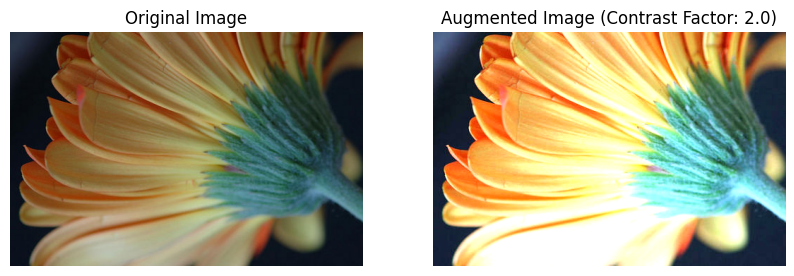

In [22]:
# Function to apply contrast enhancement
def apply_contrast(image, contrast_factor):
    return cv2.convertScaleAbs(image, alpha=contrast_factor, beta=0)

# Function to calculate image contrast using histogram
def calculate_image_contrast(image):
    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Calculate the difference between the max and min pixel values
    contrast = np.max(gray) - np.min(gray)
    return contrast

# Function to determine contrast factor using fuzzy logic
def fuzzy_contrast_adjustment(image):
    # Calculate image contrast
    contrast = calculate_image_contrast(image)
    
    # Define fuzzy sets for contrast levels (low, medium, high)
    x = np.arange(0, 256, 1)  # Contrast levels (0 to 255)
    
    low = fuzz.trapmf(x, [0, 0, 50, 100])
    medium = fuzz.trimf(x, [50, 128, 200])
    high = fuzz.trapmf(x, [150, 200, 255, 255])
    
    # Fuzzify the image contrast
    contrast_level = fuzz.interp_membership(x, low, contrast) + fuzz.interp_membership(x, medium, contrast) + fuzz.interp_membership(x, high, contrast)
    
    # Define fuzzy rules
    if contrast_level < 0.2:
        contrast_factor = 1.0  # Low contrast, apply less enhancement
    elif 0.2 <= contrast_level <= 0.6:
        contrast_factor = 1.5  # Medium contrast, apply moderate enhancement
    else:
        contrast_factor = 2.0  # High contrast, apply strong enhancement
    
    return contrast_factor

# Read image
image = cv2.imread(r"flowers/daisy/5673728_71b8cb57eb.jpg")

# Determine the contrast factor using fuzzy logic
contrast_factor = fuzzy_contrast_adjustment(image)

# Apply contrast adjustment
augmented_image = apply_contrast(image, contrast_factor)

# Display the original and augmented images
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(augmented_image, cv2.COLOR_BGR2RGB))
plt.title(f"Augmented Image (Contrast Factor: {contrast_factor})")
plt.axis('off')

plt.show()
